In [1]:
# Experiment 08 — Quantum Fourier Transform and Phase Estimation

In [2]:
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import numpy as np

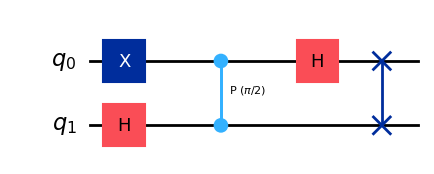

In [3]:
# Create a two-qubit circuit
qft = QuantumCircuit(2)

# Prepare the |01> state
qft.x(0)

# Apply the Quantum Fourier Transform
qft.h(1)
qft.cp(np.pi / 2, 0, 1)
qft.h(0)
qft.swap(0, 1)

# Display the QFT circuit
display(qft.draw("mpl"))

In [4]:
# Calculate the output state
qft_state = Statevector.from_instruction(qft)

print("QFT Statevector:")
print(np.round(qft_state.data, 4))

print("\nMeasurement Probabilities:")
print(qft_state.probabilities_dict())

QFT Statevector:
[ 0.5+0.j   0. +0.5j -0.5+0.j  -0. -0.5j]

Measurement Probabilities:
{np.str_('00'): np.float64(0.2499999999999999), np.str_('01'): np.float64(0.2499999999999999), np.str_('10'): np.float64(0.2499999999999999), np.str_('11'): np.float64(0.2499999999999999)}


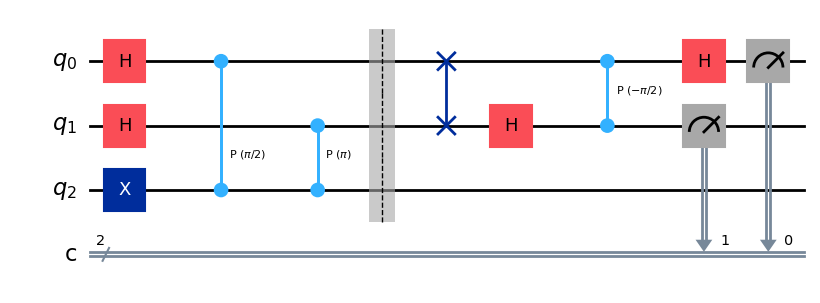

In [5]:
# Create a circuit with 2 counting qubits and 1 target qubit
qpe = QuantumCircuit(3, 2)

# Prepare the target qubit in |1>
qpe.x(2)

# Apply Hadamard gates to the counting qubits
qpe.h([0, 1])

# Apply controlled phase rotations
qpe.cp(np.pi / 2, 0, 2)
qpe.cp(np.pi, 1, 2)

qpe.barrier()

# Apply inverse QFT
qpe.swap(0, 1)
qpe.h(1)
qpe.cp(-np.pi / 2, 0, 1)
qpe.h(0)

# Measure the counting qubits
qpe.measure([0, 1], [0, 1])

# Display the circuit
display(qpe.draw("mpl"))

Phase Estimation Counts: {'01': 533, '11': 234, '10': 257}


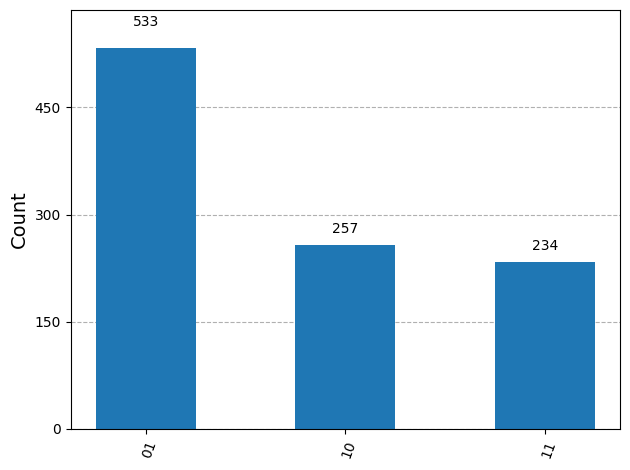

In [6]:
# Run the phase estimation circuit
simulator = AerSimulator()

result = simulator.run(
    transpile(qpe, simulator),
    shots=1024,
    seed_simulator=42
).result()

qpe_counts = result.get_counts()

print("Phase Estimation Counts:", qpe_counts)

# Display the measurement histogram
display(plot_histogram(qpe_counts))

In [7]:
# Find the most frequently measured bitstring
measured_bits = max(qpe_counts, key=qpe_counts.get)

# Convert the binary result into a phase
decimal_value = int(measured_bits, 2)
estimated_phase = decimal_value / 4

print("Measured Binary State:", measured_bits)
print("Decimal Value:", decimal_value)
print("Estimated Phase:", estimated_phase)
print("Expected Phase:", 0.25)

Measured Binary State: 01
Decimal Value: 1
Estimated Phase: 0.25
Expected Phase: 0.25
